In [9]:
from google.colab import drive, userdata
drive.mount('/content/drive')

token = userdata.get('GH_TOKEN')
![ -d /content/yuca_transfer ] || git clone https://{token}@github.com/Frank-Dev007/yuca_transfer.git /content/yuca_transfer
%cd /content/yuca_transfer
!git pull
!git config user.name "jdbcamilo"
!git config user.email "juancamilo0350@gmail.com"

!python scripts/preparar_datos.py
!ls src
!nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/yuca_transfer
Already up to date.
Tamaño del zip (MB): 1354.1
Contenido de data/: ['cassavaleafdata', 'cassavaleafdata.zip']
data.py  evaluate.py  __init__.py  models.py  __pycache__  train.py  utils.py
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [10]:
%%writefile src/models.py
import torch.nn as nn
from torchvision import models

def crear_modelo(nombre, n_clases=5):
    """Backbone preentrenado en ImageNet, totalmente congelado, con una cabeza lineal nueva entrenable."""
    if nombre == "mobilenet_v2":
        modelo = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        for p in modelo.parameters():
            p.requires_grad = False
        modelo.classifier = nn.Linear(modelo.last_channel, n_clases)   # 1280 -> 5
    elif nombre == "resnet18":
        modelo = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in modelo.parameters():
            p.requires_grad = False
        modelo.fc = nn.Linear(modelo.fc.in_features, n_clases)        # 512 -> 5
    else:
        raise ValueError(f"Modelo desconocido: {nombre}")
    return modelo

def descongelar_ultimo_bloque(modelo, nombre):
    """E2: vuelve entrenable el bloque final del backbone."""
    if nombre == "mobilenet_v2":
        bloque = modelo.features[-2:]
    elif nombre == "resnet18":
        bloque = modelo.layer4
    for p in bloque.parameters():
        p.requires_grad = True
    return modelo

Overwriting src/models.py


In [11]:
%%writefile src/train.py
import os, time
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from src.data import CLASES
from src.evaluate import calcular_metricas, imprimir_metricas, guardar_matriz_confusion, guardar_json

def poner_modo_entrenamiento(modelo):
    """Modo entrenamiento, pero las BatchNorm congeladas se quedan en modo evaluación
    para que el backbone congelado no cambie sus estadísticas internas."""
    modelo.train()
    for capa in modelo.modules():
        if isinstance(capa, nn.BatchNorm2d) and not any(p.requires_grad for p in capa.parameters()):
            capa.eval()

def predecir(modelo, loader, dispositivo):
    modelo.eval()
    reales, preds = [], []
    with torch.no_grad():
        for x, y in loader:
            salida = modelo(x.to(dispositivo, non_blocking=True))
            preds.append(salida.argmax(1).cpu())
            reales.append(y)
    return torch.cat(reales).numpy(), torch.cat(preds).numpy()

def entrenar(modelo, loaders, dispositivo, epocas, lr, ruta_checkpoint):
    modelo.to(dispositivo)
    optimizador = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=lr)
    criterio = nn.CrossEntropyLoss()
    historial, mejor_f1, mejor_epoca = [], -1.0, 0
    t0 = time.time()
    for epoca in range(1, epocas + 1):
        # Entrenamiento
        poner_modo_entrenamiento(modelo)
        suma_perdida, aciertos, n = 0.0, 0, 0
        for x, y in loaders["train"]:
            x, y = x.to(dispositivo, non_blocking=True), y.to(dispositivo, non_blocking=True)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = criterio(salida, y)
            perdida.backward()
            optimizador.step()
            suma_perdida += perdida.item() * len(y)
            aciertos += (salida.argmax(1) == y).sum().item()
            n += len(y)
        # Validación
        modelo.eval()
        suma_val, n_val, reales, preds = 0.0, 0, [], []
        with torch.no_grad():
            for x, y in loaders["validation"]:
                x, y = x.to(dispositivo, non_blocking=True), y.to(dispositivo, non_blocking=True)
                salida = modelo(x)
                suma_val += criterio(salida, y).item() * len(y)
                n_val += len(y)
                preds.append(salida.argmax(1).cpu())
                reales.append(y.cpu())
        m = calcular_metricas(torch.cat(reales).numpy(), torch.cat(preds).numpy())
        fila = {"epoca": epoca,
                "perdida_train": suma_perdida / n, "accuracy_train": aciertos / n,
                "perdida_val": suma_val / n_val, "accuracy_val": m["accuracy"],
                "macro_f1_val": m["macro_f1"], "segundos_acumulados": time.time() - t0}
        historial.append(fila)
        print(f"Época {epoca:2d} | pérdida train {fila['perdida_train']:.4f} | "
              f"pérdida val {fila['perdida_val']:.4f} | macro-F1 val {fila['macro_f1_val']:.4f} | "
              f"{fila['segundos_acumulados']:.0f} s")
        if m["macro_f1"] > mejor_f1:              # decisión 11: mejor macro-F1 en validación
            mejor_f1, mejor_epoca = m["macro_f1"], epoca
            torch.save(modelo.state_dict(), ruta_checkpoint)
    tiempo = time.time() - t0
    modelo.load_state_dict(torch.load(ruta_checkpoint, map_location=dispositivo))
    return pd.DataFrame(historial), {"mejor_epoca": mejor_epoca, "mejor_macro_f1_val": mejor_f1,
                                     "tiempo_entrenamiento_s": tiempo}

def medir_inferencia_ms(modelo, loader, dispositivo, n_lotes=20):
    """Tiempo del modelo por imagen (lotes de 32, sin contar la carga de imágenes)."""
    modelo.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for i, (x, _) in enumerate(loader):
            x = x.to(dispositivo)
            if dispositivo.type == "cuda":
                torch.cuda.synchronize()
            t = time.time()
            modelo(x)
            if dispositivo.type == "cuda":
                torch.cuda.synchronize()
            if i > 0:                          # el primer lote se descarta (calentamiento)
                total += time.time() - t
                n += len(x)
            if i >= n_lotes:
                break
    return total / n * 1000

def graficar_curvas(historial, ruta, titulo):
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
    ejes[0].plot(historial.epoca, historial.perdida_train, "o-", label="train")
    ejes[0].plot(historial.epoca, historial.perdida_val, "o-", label="validación")
    ejes[0].set_title("Pérdida")
    ejes[0].set_xlabel("Época")
    ejes[0].legend()
    ejes[1].plot(historial.epoca, historial.accuracy_train, "o-", label="accuracy train")
    ejes[1].plot(historial.epoca, historial.accuracy_val, "o-", label="accuracy validación")
    ejes[1].plot(historial.epoca, historial.macro_f1_val, "o-", label="macro-F1 validación")
    ejes[1].set_title("Métricas")
    ejes[1].set_xlabel("Época")
    ejes[1].legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.savefig(ruta, dpi=150)
    plt.show()

def ejecutar_experimento(nombre, modelo, loaders, dispositivo, epocas, lr, semilla, descripcion, extra=None):
    carpeta = f"results/{nombre}"
    os.makedirs(carpeta, exist_ok=True)
    os.makedirs("checkpoints", exist_ok=True)
    ruta_ckpt = f"checkpoints/{nombre}.pt"

    historial, info = entrenar(modelo, loaders, dispositivo, epocas, lr, ruta_ckpt)
    historial.to_csv(f"{carpeta}/historial.csv", index=False)
    graficar_curvas(historial, f"{carpeta}/curvas.png", f"{nombre} · {descripcion}")

    y_val, p_val = predecir(modelo, loaders["validation"], dispositivo)
    y_test, p_test = predecir(modelo, loaders["test"], dispositivo)
    m_val, m_test = calcular_metricas(y_val, p_val), calcular_metricas(y_test, p_test)
    imprimir_metricas(m_val, "Validación (mejor época)")
    print()
    imprimir_metricas(m_test, "Test")
    guardar_matriz_confusion(y_test, p_test, f"{carpeta}/matriz_confusion_test.png",
                             f"{nombre} · {descripcion} · Test")

    # Predicciones de test, para el análisis de errores
    pd.DataFrame({"ruta": loaders["test"].dataset.rutas,
                  "real": [CLASES[i] for i in y_test],
                  "predicha": [CLASES[i] for i in p_test]}).to_csv(f"{carpeta}/predicciones_test.csv", index=False)

    resumen = {"experimento": nombre, "descripcion": descripcion, "semilla": semilla,
               "epocas": epocas, "lr": lr, "batch_size": loaders["train"].batch_size, **info,
               "validacion": m_val, "test": m_test,
               "tiempo_inferencia_ms_por_imagen": medir_inferencia_ms(modelo, loaders["test"], dispositivo),
               "parametros_totales": sum(p.numel() for p in modelo.parameters()),
               "parametros_entrenables": sum(p.numel() for p in modelo.parameters() if p.requires_grad),
               "tamano_checkpoint_mb": os.path.getsize(ruta_ckpt) / 1e6,
               "gpu": torch.cuda.get_device_name(0) if dispositivo.type == "cuda" else "cpu",
               **(extra or {})}
    guardar_json(resumen, f"{carpeta}/metricas.json")
    print(f"\nMejor época: {info['mejor_epoca']} | entrenamiento: {info['tiempo_entrenamiento_s']:.0f} s | "
          f"inferencia: {resumen['tiempo_inferencia_ms_por_imagen']:.2f} ms/imagen | "
          f"parámetros entrenables: {resumen['parametros_entrenables']:,}")
    return resumen

Overwriting src/train.py


In [ ]:
import sys, torch
sys.path.append("/content/yuca_transfer")
from src.utils import fijar_semilla, obtener_dispositivo
from src.data import crear_dataloaders
from src.models import crear_modelo
from src.train import ejecutar_experimento

SEED, BATCH, LR = 42, 32, 0.001    # protocolo: decisiones 5, 9 y 8
fijar_semilla(SEED)
dispositivo = obtener_dispositivo()
loaders = crear_dataloaders(batch_size=BATCH, seed=SEED)
print(dispositivo, {s: len(l.dataset) for s, l in loaders.items()})

cuda {'train': 5616, 'validation': 1878, 'test': 1874}


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 149MB/s]


Época  1 | pérdida train 0.8776 | pérdida val 0.7157 | macro-F1 val 0.6297 | 53 s


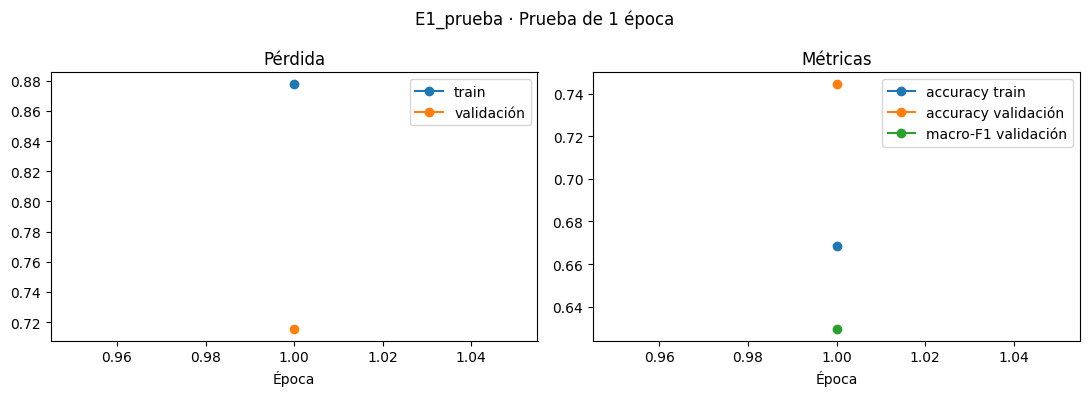

Validación (mejor época): accuracy = 0.7444 | macro-F1 = 0.6297
   cbb      recall = 0.318   F1 = 0.430   (n = 151)
   cbsd     recall = 0.785   F1 = 0.720   (n = 479)
   cgm      recall = 0.451   F1 = 0.567   (n = 257)
   cmd      recall = 0.914   F1 = 0.846   (n = 886)
   healthy  recall = 0.457   F1 = 0.585   (n = 105)

Test: accuracy = 0.7481 | macro-F1 = 0.6125
   cbb      recall = 0.279   F1 = 0.393   (n = 154)
   cbsd     recall = 0.807   F1 = 0.727   (n = 477)
   cgm      recall = 0.470   F1 = 0.575   (n = 253)
   cmd      recall = 0.921   F1 = 0.858   (n = 885)
   healthy  recall = 0.381   F1 = 0.510   (n = 105)


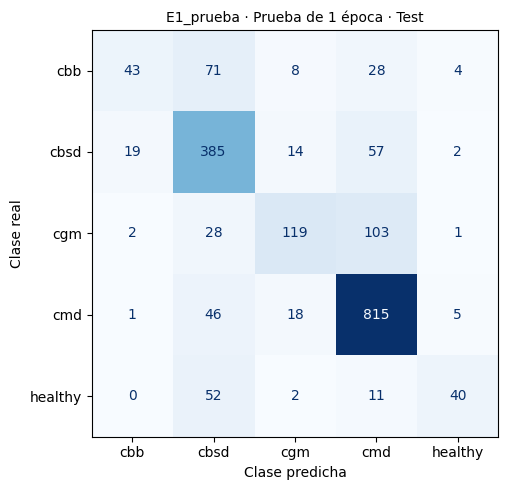


Mejor época: 1 | entrenamiento: 53 s | inferencia: 1.24 ms/imagen | parámetros entrenables: 6,405


In [ ]:
fijar_semilla(SEED)
modelo = crear_modelo("mobilenet_v2")
_ = ejecutar_experimento("E1_prueba", modelo, loaders, dispositivo, epocas=1, lr=LR, semilla=SEED,
                         descripcion="Prueba de 1 época")

In [ ]:
!git pull
!git add src results/E1_prueba checkpoints/E1_prueba.pt
!git commit -m "E1: models.py, train.py y prueba de 1 época"
!git push

Already up to date.
[main 29fcc60] E1: models.py, train.py y prueba de 1 época
 8 files changed, 2143 insertions(+)
 create mode 100644 checkpoints/E1_prueba.pt
 create mode 100644 results/E1_prueba/curvas.png
 create mode 100644 results/E1_prueba/historial.csv
 create mode 100644 results/E1_prueba/matriz_confusion_test.png
 create mode 100644 results/E1_prueba/metricas.json
 create mode 100644 results/E1_prueba/predicciones_test.csv
 create mode 100644 src/models.py
 create mode 100644 src/train.py
Enumerating objects: 18, done.
Counting objects: 100% (18/18), done.
Delta compression using up to 2 threads
Compressing objects: 100% (14/14), done.
Writing objects: 100% (14/14), 8.13 MiB | 8.90 MiB/s, done.
Total 14 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/Frank-Dev007/yuca_transfer.git
   a2224bb..29fcc60  main -> main


Época  1 | pérdida train 0.8626 | pérdida val 0.7086 | macro-F1 val 0.6560 | 54 s
Época  2 | pérdida train 0.6856 | pérdida val 0.6654 | macro-F1 val 0.6553 | 105 s
Época  3 | pérdida train 0.6266 | pérdida val 0.6577 | macro-F1 val 0.6981 | 161 s
Época  4 | pérdida train 0.5986 | pérdida val 0.6399 | macro-F1 val 0.6918 | 212 s
Época  5 | pérdida train 0.5723 | pérdida val 0.6246 | macro-F1 val 0.7002 | 265 s
Época  6 | pérdida train 0.5567 | pérdida val 0.6232 | macro-F1 val 0.6955 | 316 s
Época  7 | pérdida train 0.5497 | pérdida val 0.6198 | macro-F1 val 0.6953 | 369 s
Época  8 | pérdida train 0.5288 | pérdida val 0.6219 | macro-F1 val 0.6960 | 420 s
Época  9 | pérdida train 0.5234 | pérdida val 0.6496 | macro-F1 val 0.7040 | 472 s
Época 10 | pérdida train 0.5097 | pérdida val 0.6109 | macro-F1 val 0.7016 | 524 s


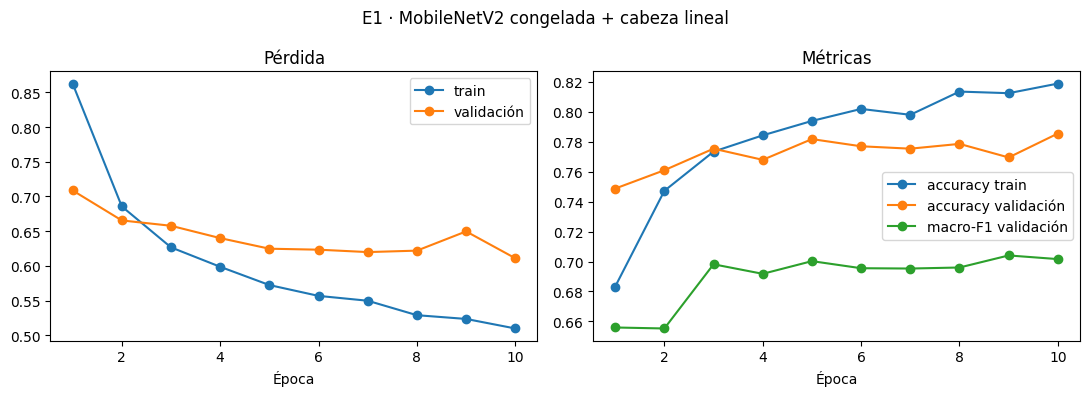

Validación (mejor época): accuracy = 0.7694 | macro-F1 = 0.7040
   cbb      recall = 0.583   F1 = 0.542   (n = 151)
   cbsd     recall = 0.772   F1 = 0.718   (n = 479)
   cgm      recall = 0.700   F1 = 0.723   (n = 257)
   cmd      recall = 0.841   F1 = 0.868   (n = 886)
   healthy  recall = 0.590   F1 = 0.670   (n = 105)

Test: accuracy = 0.7689 | macro-F1 = 0.6944
   cbb      recall = 0.539   F1 = 0.476   (n = 154)
   cbsd     recall = 0.795   F1 = 0.741   (n = 477)
   cgm      recall = 0.723   F1 = 0.725   (n = 253)
   cmd      recall = 0.832   F1 = 0.872   (n = 885)
   healthy  recall = 0.571   F1 = 0.659   (n = 105)


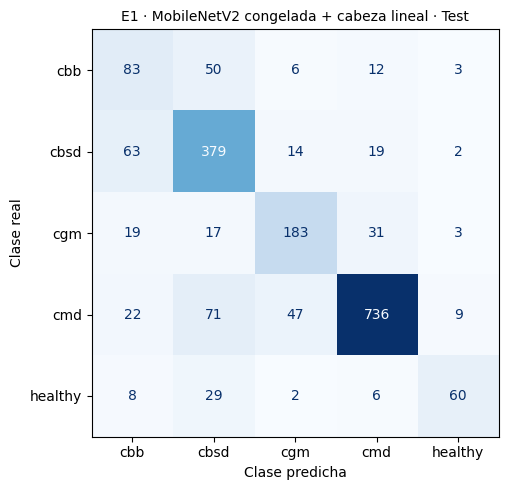


Mejor época: 9 | entrenamiento: 524 s | inferencia: 1.14 ms/imagen | parámetros entrenables: 6,405


In [12]:
fijar_semilla(SEED)
modelo = crear_modelo("mobilenet_v2")
r_e1 = ejecutar_experimento("E1", modelo, loaders, dispositivo, epocas=10, lr=LR, semilla=SEED,
                            descripcion="MobileNetV2 congelada + cabeza lineal")

In [13]:
!git pull
!git add results/E1 checkpoints/E1.pt
!git commit -m "E1: MobileNetV2 congelada + cabeza lineal (10 épocas)"
!git push

Already up to date.
[main 6f0b624] E1: MobileNetV2 congelada + cabeza lineal (10 épocas)
 6 files changed, 1974 insertions(+)
 create mode 100644 checkpoints/E1.pt
 create mode 100644 results/E1/curvas.png
 create mode 100644 results/E1/historial.csv
 create mode 100644 results/E1/matriz_confusion_test.png
 create mode 100644 results/E1/metricas.json
 create mode 100644 results/E1/predicciones_test.csv
Enumerating objects: 14, done.
Counting objects: 100% (14/14), done.
Delta compression using up to 2 threads
Compressing objects: 100% (11/11), done.
Writing objects: 100% (11/11), 8.18 MiB | 6.40 MiB/s, done.
Total 11 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/Frank-Dev007/yuca_transfer.git
   3fa286b..6f0b624  main -> main


In [14]:
!cp "/content/drive/MyDrive/Colab Notebooks/03_E1_feature_extraction.ipynb" notebooks/
!git add notebooks/03_E1_feature_extraction.ipynb
!git commit -m "Notebook E1"
!git push

cp: cannot stat '/content/drive/MyDrive/Colab Notebooks/03_E1_feature_extraction.ipynb': No such file or directory
fatal: pathspec 'notebooks/03_E1_feature_extraction.ipynb' did not match any files
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   results/E1_prueba/historial.csv
	modified:   results/E1_prueba/metricas.json
	modified:   src/models.py

no changes added to commit (use "git add" and/or "git commit -a")
Everything up-to-date


In [18]:
import json
for n in ["E1_prueba", "E1"]:
    m = json.load(open(f"results/{n}/metricas.json"))
    print(f"{n:10s} épocas: {m['epocas']} | mejor época: {m['mejor_epoca']} | macro-F1 test: {m['test']['macro_f1']:.4f}")

E1_prueba  épocas: 1 | mejor época: 1 | macro-F1 test: 0.6125
E1         épocas: 10 | mejor época: 9 | macro-F1 test: 0.6944


In [19]:
!git mv results/E1 results/_tmp && git mv results/E1_prueba results/E1 && git mv results/_tmp results/E1_prueba
!git mv checkpoints/E1.pt checkpoints/_tmp.pt && git mv checkpoints/E1_prueba.pt checkpoints/E1.pt && git mv checkpoints/_tmp.pt checkpoints/E1_prueba.pt

for n in ["E1", "E1_prueba"]:                       # corregir el nombre dentro de cada metricas.json
    ruta = f"results/{n}/metricas.json"
    m = json.load(open(ruta)); m["experimento"] = n
    json.dump(m, open(ruta, "w"), indent=2, ensure_ascii=False)
    print(n, "épocas:", m["epocas"])

!git add results checkpoints
!git commit -m "Corrige nombres: E1 = 10 épocas, E1_prueba = 1 época"
!git push

E1 épocas: 1
E1_prueba épocas: 10
[main 3ecc112] Corrige nombres: E1 = 10 épocas, E1_prueba = 1 época
 12 files changed, 841 insertions(+), 841 deletions(-)
Enumerating objects: 15, done.
Counting objects: 100% (15/15), done.
Delta compression using up to 2 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 1.35 KiB | 1.35 MiB/s, done.
Total 8 (delta 5), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (5/5), completed with 4 local objects.
To https://github.com/Frank-Dev007/yuca_transfer.git
   6f0b624..3ecc112  main -> main
